# 00. 사전 점검

수업 전에 10분 안에 끝내는 점검입니다. 설치가 맞게 되었는지, 시뮬레이터와 그림이 도는지, 그리고 `RUNPOD_BASE_URL`이 무엇에 쓰이는지만 확인합니다. vLLM 내용은 01부터 시작합니다.

## 수업 시간표

| 절 | 내용 | 분 |
|---|---|---:|
| 1 | 설치와 실행 위치 | 3 |
| 2 | 키와 GPU가 필요 없는 이유 | 2 |
| 3 | 시뮬레이터 불러오기 | 2 |
| 4 | 그림이 그려지는지 확인 | 1 |
| 5 | 시간표와 `RUNPOD_BASE_URL` | 2 |

## 학습 목표

- 설치는 저장소 루트에서 한 번, 실행은 `Day07_new/`에서 한다는 구분을 말한다.
- 00~04b에 키와 GPU가 필요 없다는 것을 확인한다.
- 시뮬레이터와 그림이 도는지 직접 본다.
- `RUNPOD_BASE_URL`이 05, 06의 선택 셀에만 쓰인다는 것을 안다.

## 1. 설치와 실행 위치

설치는 저장소 루트에서 한 번만 합니다. 실행은 `Day07_new/` 폴더에서 합니다.

```bash
uv sync --locked          # 저장소 루트에서 한 번만
cd Day07_new
uv run jupyter lab
```

`Day07_new/`에는 `pyproject.toml`이 없고 루트의 uv workspace 환경(`.venv`)을 그대로 씁니다. 그래서 이 폴더에서 `uv sync`를 쳐도 uv가 위로 올라가 루트 프로젝트를 쓰고, 패키지는 바뀌지 않습니다(`uv sync --dry-run`이 `Would make no changes`를 냅니다). 그래도 폴더 안에서는 치지 않는 습관을 들입니다. `Day07` 같은 workspace 멤버 폴더에서 같은 명령을 치면 그 Day에 필요 없는 패키지가 지워지기 때문이고, 복구는 루트에서 `uv sync --locked`입니다. 루트 `AGENTS.md` 3절에 있는 규칙입니다.

아래 셀은 지금 어떤 환경에서 도는지 보여 줍니다. `sys.prefix`가 저장소 루트의 `.venv`를 가리키고 작업 폴더 이름이 `Day07_new`이면 맞게 된 것입니다.

In [1]:
import pathlib
import platform
import sys
from importlib.metadata import version

print("Python        :", platform.python_version())
for name in ("numpy", "pandas", "matplotlib"):
    print(f"{name:<14}:", version(name))
print("sys.prefix    :", sys.prefix)
print("작업 폴더 이름 :", pathlib.Path.cwd().name)

Python        : 3.13.14
numpy         : 2.5.4
pandas        : 3.1.0
matplotlib    : 3.11.2
sys.prefix    : /Users/jhj/Desktop/sds_ax_advanced_class/.venv
작업 폴더 이름 : Day07_new


## 2. 키와 GPU가 필요 없는 이유

00~04의 코드 셀은 네트워크를 부르지 않고 API 키도 GPU도 쓰지 않습니다. 호출 규모는 0회입니다. 이 자료를 쓴 사람은 vLLM v0.32.0 소스와 공식 문서를 읽었습니다. 일부는 GPU 없이 CPU에서 실제 vLLM 클래스를 불러 시뮬레이터와 맞춰 보았습니다(`실제 클래스 실행`, `docs/REFERENCE_RUN.md`). 이것은 클래스 호출이지 서버 실행이 아닙니다. 모델을 올린 vLLM 서버나 수업 Pod에서 값을 관찰한 적은 없습니다(`docs/SOURCES.md`의 고정한 기준). 코드를 읽은 결과를 설명하고, 그 규칙을 작게 흉내 낸 시뮬레이터로 직접 관찰합니다.

기준 버전을 두 가지로 나누어 말하겠습니다. 소스와 공식 문서는 v0.32.0이고, 수업 때 쓰는 Pod의 이미지는 `Day07/README.md:75`에 vLLM v0.28.1rc1 dev 빌드로 적혀 있습니다(R-01). 둘은 같지 않을 수 있으므로 본문은 "v0.32.0 코드는 이렇다"라고 쓰고 "수업 서버가 이렇게 동작한다"라고 쓰지 않습니다. 서버가 보고하는 실제 버전은 `GET /version`으로 확인합니다. 순서는 05의 절 7이 가리키는 `docs/SOURCES.md`의 `## Pod 점검 항목`에 있습니다.

다음 셀은 `vllm_lab`의 5개 모듈을 불러오고, 이 환경에 `vllm`과 `torch`가 올라와 있지 않다는 것을 확인합니다.

In [2]:
import vllm_lab
from vllm_lab import agent_sim, kv_math, kv_sim, sched_sim, view

print("기준 버전 :", vllm_lab.VLLM_VERSION)
print("기준 커밋 :", vllm_lab.VLLM_COMMIT)
print("불러온 모듈:", [m.__name__ for m in (agent_sim, kv_math, kv_sim, sched_sim, view)])
print("vllm  이 sys.modules에 있는가:", "vllm" in sys.modules)
print("torch 가 sys.modules에 있는가:", "torch" in sys.modules)

기준 버전 : 0.32.0
기준 커밋 : 5df63a7203cdb9328d824a27b682e77c7b9928be
불러온 모듈: ['vllm_lab.agent_sim', 'vllm_lab.kv_math', 'vllm_lab.kv_sim', 'vllm_lab.sched_sim', 'vllm_lab.view']
vllm  이 sys.modules에 있는가: False
torch 가 sys.modules에 있는가: False


## 3. 시뮬레이터 불러오기

**이것은 vLLM이 아니라 수업용 모델입니다.** `kv_sim.KVManagerSim`은 block 풀과 prefix 적중의 규칙 일부만 흉내 냅니다. watermark, sliding window, KV connector, 실제 KV 값, 실제 hash 값은 모델링하지 않았고, 모델링하지 않은 목록은 모듈의 `NOT_MODELED`에 있습니다. 출력은 "vLLM이 이렇게 동작했다"가 아니라 "이 모델이 이렇게 계산했다"입니다.

일부 규칙은 코드를 읽어 맞췄습니다. block 하나의 기본 크기는 16 token입니다([`cache.py` 72행](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/config/cache.py#L72), P2-04). `BlockPool`은 첫 free block을 꺼내 null block(ID 0)으로 쓰므로 실제 할당 ID는 1부터입니다([`block_pool.py` 187행](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/block_pool.py#L187), P2-08). 이 두 줄이 아래 계산의 전부입니다.

**먼저 예측하세요.** 54 token짜리 요청 `doc` 하나를 block 8개(null 포함)짜리 pool에 스케줄하면 block을 몇 개 받고, 마지막 block ID는 몇일까요? 실행 전에 두 숫자를 적어 두세요.

In [3]:
sim = kv_sim.KVManagerSim(8)          # block 8개, 그중 ID 0은 null block
TOKENS = 54                           # 해보기 1에서 이 값만 바꿉니다
doc = sim.add_request("doc", list(range(TOKENS)))
result = sim.schedule(doc)
print("block 수 :", len(result.new_block_ids), "/ 첫 block ID :", result.new_block_ids[0], "/ 마지막 block ID :", result.new_block_ids[-1])
view.table([result.to_row()])

block 수 : 4 / 첫 block ID : 1 / 마지막 block ID : 4


,request_id,hit_tokens,hit_block_ids,new_block_ids,block_table,num_computed_tokens,num_scheduled_tokens,num_lookahead_tokens,evicted_block_ids
0,doc,0,[],"[1, 2, 3, 4]","[1, 2, 3, 4]",54,54,0,[]


**관찰할 것.** 표의 `block_table`과 `new_block_ids` 칸을 읽으세요. 두 칸의 길이가 예측과 맞는지, 첫 값이 0이 아닌 이유가 위의 어느 줄 때문인지 말해 보세요.

다음 셀은 같은 pool을 그림으로 그립니다. 칸 안 글자는 ASCII만 씁니다.

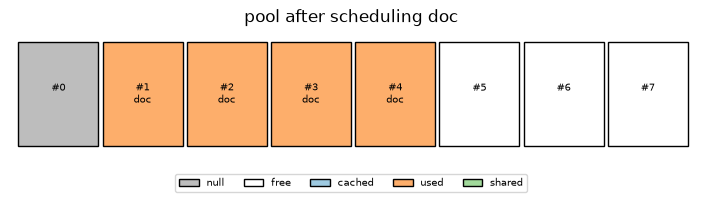

In [4]:
fig = view.block_grid(sim.snapshot(), ncols=8, title="pool after scheduling doc")
fig

## 4. 그림이 그려지는지 확인

위 셀 출력에 8칸짜리 그림이 보여야 합니다. 회색은 null block, 주황은 `doc`이 쓰는 block, 흰색은 비어 있는 block입니다. 그림이 보이지 않고 글자만 보이면 matplotlib 백엔드가 노트북에 연결되지 않은 것이므로 강사에게 알려 주세요. 시간이 필요한 그림(`view.timeline`)의 값은 모두 toy 상수이며 측정이 아닙니다.

## 5. 시간표와 `RUNPOD_BASE_URL`

00~04는 위처럼 `vllm_lab`만으로 끝까지 실행됩니다. 서버가 필요한 곳은 05와 06의 선택 셀뿐이고, 그 셀들은 `RUN_POD = False`로 잠겨 있습니다. `RUNPOD_BASE_URL`은 그 선택 셀이 접속할 서버 주소를 `Day07_new/.env`에서 읽을 때만 쓰입니다. 값을 채우지 않아도 정상이며, 05와 06도 선택 셀을 건너뛰고 끝까지 실행됩니다.

`.env` 파일이 없으면 `.env.example`을 보고 직접 만듭니다. 이 노트북은 값을 절대 출력하지 않고 `설정됨`과 `미설정`만 말합니다. 아직 확인되지 않은 것도 하나 있습니다. 수업 Pod가 파서 관련 플래그로 떴는지는 `Day07/README.md`에 적혀 있지 않습니다(R-04(미확인)). 05, 06에서 도구 호출을 시험하기 전에 강사에게 확인해야 합니다.

In [5]:
RUN_POD = False   # 00은 서버에 접속하지 않습니다. 05, 06의 선택 셀에서만 쓰는 이름입니다
print("RUNPOD_BASE_URL:", view.env_status("RUNPOD_BASE_URL"))

RUNPOD_BASE_URL: 미설정


**관찰할 것.** `미설정`이 나와도 실패가 아닙니다. 위 셀은 설정 여부만 말하고 값을 쓰지 않습니다. 01~04는 이 값을 쓰지 않고, 05와 06도 `RUN_POD = False`이면 서버 주소로 쓰지 않습니다.

| 노트북 | 시간 | 서버 필요 |
|---|---:|---|
| 00 사전 점검 | 10분 | 없음 |
| 01, 02a, 02b, 02c, 03, 04, 04b (Part 1~4) | 4시간 이론 | 없음 |
| 05, 06 (Part 5~6) | 실습 | 선택 셀만(`RUN_POD = False`가 기본) |

## 직접 해보기

### 해보기 1

3번 절 코드 셀의 `TOKENS`를 54에서 65로 바꾸고 그 셀부터 다시 실행합니다. 실행 전에 block 수가 몇 개가 될지 먼저 적으세요. 그림에서 `doc`이 쓰는 칸이 어떻게 달라지는지 봅니다.

## 확인 질문

1. 왜 `uv sync`는 저장소 루트에서 하고, Day 폴더 안에서는 하지 않는가. `Day07_new/`와 `Day07/`는 어떻게 다른가.
2. 05, 06의 어떤 셀만 `RUNPOD_BASE_URL` 값을 서버 주소로 쓰는가.
3. 시뮬레이터 결과와 실제 서버 결과의 차이는 무엇인가.
4. 수업 서버 버전과 이 자료의 기준 버전은 어떻게 다른가.
5. 54 token이 block 4개인 계산을 말로 설명하라.

## 블로그 함께 읽기

「Inside vLLM: 서버 시작부터 KV cache까지 소스 코드 톺아보기」, Jongsu Liam Kim, https://blog.liam.kim/posts/2026/10/Inside-vLLM/ (절 제목으로만 참조합니다).

| 블로그 절 | 읽을 때 볼 점 |
|---|---|
| Introduction | 전체 흐름의 지도로만 읽으세요. 이 절의 Model Runner V2 서술은 코드와 다릅니다. 코드가 맞고, 환경변수를 정하지 않으면 조건이 맞을 때만 V2를 고릅니다(P2-15). |

## 정리

- 설치는 루트에서 한 번(`uv sync --locked`), 실행은 `Day07_new/`에서 합니다. 폴더 안에서는 `uv sync`를 하지 않습니다.
- 00~04는 키, GPU, 서버 없이 돌고, `RUNPOD_BASE_URL`은 05, 06의 선택 셀에서만 쓰입니다.
- 01로 넘기는 것: 요청 한 건이 서버 안에서 지나가는 길을 객체와 프로세스 이름으로 말하는 일입니다.

## 참고한 근거

P2-04 같은 번호는 근거 대장(`docs/sources/`)의 행 번호입니다.

P2-04, P2-08, P2-15, R-01, R-04(미확인)